
Dataset:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst texture  worst perimeter  worst area  \
0   

c:\Users\KHODAL INFOTECH\Desktop\pyhton\dsip\.venv\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(



========== MODEL EVALUATION ==========
Accuracy: 0.9824561403508771
Precision: 0.9861111111111112
Recall: 0.9861111111111112
F1 Score: 0.9861111111111112

Confusion Matrix:
[[41  1]
 [ 1 71]]

Classification Report:
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114


Actual vs Predicted:
   actual  predicted
0       0          0
1       1          1
2       0          0
3       1          1
4       0          0
5       1          1
6       1          1
7       0          0
8       0          0
9       0          0


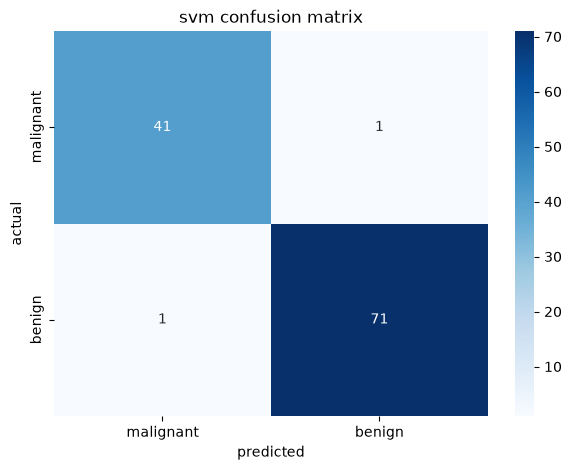

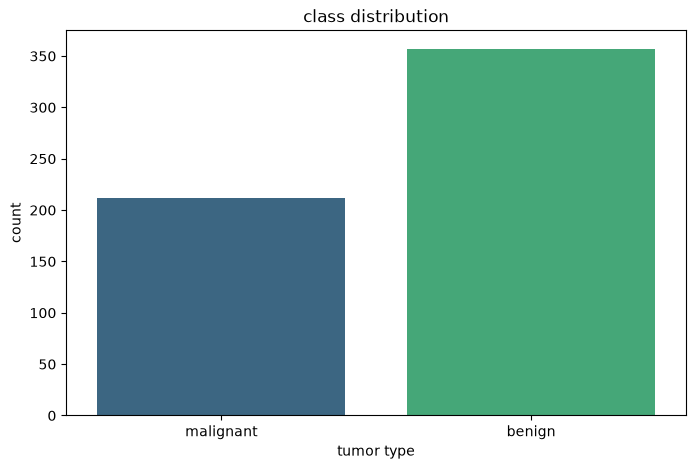

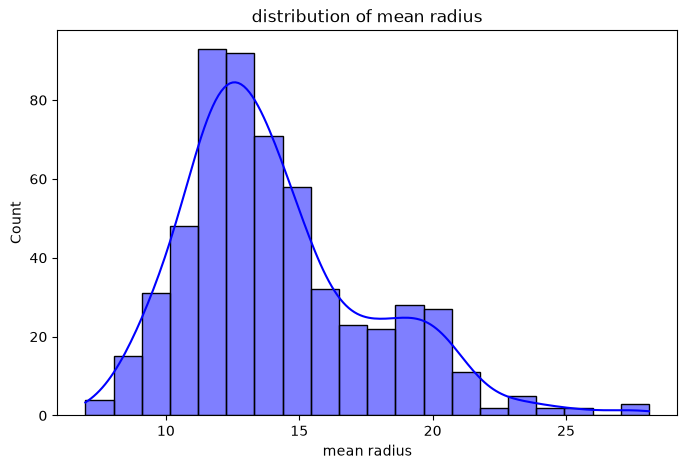


========== NEW PREDICTION ==========
Predicted Class: malignant

Prediction Probability:
[[0.97545509 0.02454491]]

========== PROGRAM COMPLETED ==========


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.metrics import classification_report
from sklearn.metrics import precision_score, recall_score, f1_score

can = load_breast_cancer()

dat = pd.DataFrame(
    can.data,
    columns=can.feature_names
)

dat['target'] = can.target

print("\nDataset:")
print(dat.head())

print("\nDataset Shape:")
print(dat.shape)

print("\nDataset Information:")
dat.info()

print("\nStatistical Summary:")
print(dat.describe())

print("\nMissing Values:")
print(dat.isnull().sum().sum())

print("\nDuplicate Values:")
print(dat.duplicated().sum())

x = dat.drop('target', axis=1)
y = dat['target']

xtr, xte, ytr, yte = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

sca = StandardScaler()

xtr = sca.fit_transform(xtr)
xte = sca.transform(xte)

mod = SVC(
    kernel='rbf',
    C=1.0,
    gamma='scale',
    probability=True,
    random_state=42
)

mod.fit(xtr, ytr)

ypred = mod.predict(xte)

prob = mod.predict_proba(xte)

acc = accuracy_score(yte, ypred)
pre = precision_score(yte, ypred)
rec = recall_score(yte, ypred)
f1 = f1_score(yte, ypred)

cm = confusion_matrix(yte, ypred)

print("\n========== MODEL EVALUATION ==========")

print("Accuracy:", acc)
print("Precision:", pre)
print("Recall:", rec)
print("F1 Score:", f1)

print("\nConfusion Matrix:")
print(cm)

print("\nClassification Report:")
print(classification_report(
    yte,
    ypred,
    target_names=can.target_names
))

res = pd.DataFrame({
    'actual': yte.values,
    'predicted': ypred
})

print("\nActual vs Predicted:")
print(res.head(10))

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=can.target_names,
    yticklabels=can.target_names
)

plt.xlabel('predicted')
plt.ylabel('actual')
plt.title('svm confusion matrix')
plt.show()

plt.figure(figsize=(8, 5))

sns.countplot(
    x=y,
    hue=y,
    palette='viridis',
    legend=False
)

plt.xticks(
    [0, 1],
    can.target_names
)

plt.xlabel('tumor type')
plt.ylabel('count')
plt.title('class distribution')
plt.show()

plt.figure(figsize=(8, 5))

sns.histplot(
    dat['mean radius'],
    bins=20,
    kde=True,
    color='blue'
)

plt.xlabel('mean radius')
plt.title('distribution of mean radius')
plt.show()

new = pd.DataFrame(
    [can.data[0]],
    columns=can.feature_names
)

new = sca.transform(new)

pre = mod.predict(new)

print("\n========== NEW PREDICTION ==========")

print("Predicted Class:", can.target_names[pre[0]])

print("\nPrediction Probability:")
print(mod.predict_proba(new))

print("\n========== PROGRAM COMPLETED ==========")
